In [18]:
%pip install seaborn

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

завантажуємо потрібні біліотеки для подальшої роботи з даними

In [2]:
companies = pd.read_csv("Unicorn_Companies.csv")

тепер основне - завантажуємо датасет.
мій датасет про компанії - єдинороги (стартапи , з оціночними вартостями більше 1млрд доларів США). отже, далі після наших запитів ми розглянемо детальніше структуру датасету. за допомогою нього ми зможемо дізнатися про те, з яких регіонів стартапи (в подальшому зможемо ставити питання чи географічне положення впливає на це), які галузі є найприбутковішими (які менеше), скільки часу потребує компанія для того, щоб вирости до рівня 1 млрд доларів США. також зможемо дізнатися , хто фінансує ці стартапи.

In [4]:
companies.head(10)

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0
1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN
2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0
4,Epic Games,$42,10/26/2018,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0
5,Canva,$40,1/8/2018,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat...",2012.0,$571.26M,NaN,26.0,8.0,NaN
6,Checkout.com,$40,5/2/2019,United Kingdom,London,Fintech,"Tiger Global Management, Insight Partners, DST...",2012.0,$1.83B,NaN,15.0,4.0,NaN
7,Instacart,$39,12/30/2014,United States,San Francisco,"Supply chain, logistics, & delivery","Khosla Ventures, Kleiner Perkins Caufield & By...",2012.0,$2.686B,NaN,29.0,12.0,NaN
8,Databricks,$38,2/5/2019,United States,San Francisco,Data management & analytics,"Andreessen Horowitz, New Enterprise Associates...",2013.0,$3.497B,NaN,29.0,8.0,NaN
9,Revolut,$33,4/26/2018,United Kingdom,London,Fintech,"index Ventures, DST Global, Ribbit Capital",2015.0,$1.716B,NaN,31.0,6.0,NaN


In [5]:
companies.shape

(1037, 13)

на цьому кроці бачимо масштаб даних: 1037 компаній (рядків) та 13 параметрів (стовпчиків).

In [7]:
companies.drop_duplicates()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0
1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN
2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0
4,Epic Games,$42,10/26/2018,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1032,Timescale,$1,2/22/2022,United States,New York,Internet software & services,"New Enterprise Associates, Benchmark, Two Sigm...",2015.0,$181.06M,NaN,7.0,2.0,NaN
1033,Scalapay,$1,2/23/2022,Italy,Milan,Fintech,"Fasanara Capital, Tiger Global Management, Bal...",2019.0,$700M,NaN,10.0,2.0,NaN
1034,Omada Health,$1,2/23/2022,United States,San Francisco,Health,"U.S. Venture Partners, dRx Capital, Andreessen...",2011.0,$449.72M,NaN,30.0,6.0,NaN
1035,BlueVoyant,$1,2/23/2022,United States,New York,Cybersecurity,"8VC, Liberty Strategic Capital, Eden Global Pa...",2017.0,$525.5M,NaN,6.0,2.0,NaN


In [8]:
companies.dtypes

Company                  str
Valuation ($B)           str
Date Joined              str
Country                  str
City                     str
Industry                 str
Select Inverstors        str
Founded Year         float64
Total Raised             str
Financial Stage          str
Investors Count      float64
Deal Terms           float64
Portfolio Exits      float64
dtype: object

за допомогою цього запиту, бачимо структуру наших даних. Вже можемо проаналізувати чи є порожні (нульові) значення, чи відповідає тип данних нашим самим данним. Отже,бачимо присутні або str ( текстові) данні або float 64 (кількісні), тепер їх зіставляємо з типом данних: начебто проблем не знайшли, адже еткстові зіставляються з данними назв компаній, країн, тощо , а кількісні із числовими значеннями. інколи, в цьому пункті можна одразу зрозуміти чи стовпчики з датою мають правильний тип і якщо ні, то одразу замінити на тип дати, щоб далі легше проводити аналітику. одразу бачимо де нульові значення , шляхом порівнння кількості всіх : 1037 із зазначенними кількрстями у звіті.

In [10]:
companies.columns

Index(['Company', 'Valuation ($B)', 'Date Joined', 'Country', 'City',
       'Industry', 'Select Inverstors', 'Founded Year', 'Total Raised',
       'Financial Stage', 'Investors Count', 'Deal Terms', 'Portfolio Exits'],
      dtype='str')

In [11]:
companies.sort_values(by='Valuation ($B)', ascending=False).head(10)

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
58,OYO Rooms,$9.6,9/25/2018,India,Gurugram,Travel,"SoftBank Group, Sequoia Capital India,Lightspe...",2012.0,$3.114B,NaN,20.0,11.0,NaN
50,ServiceTitan,$9.5,11/14/2018,United States,Glendale,Internet software & services,"Bessemer Venture Partners, ICONIQ Capital, Bat...",2012.0,$1.099B,NaN,16.0,6.0,NaN
49,OutSystems,$9.5,6/5/2018,United States,Boston,Internet software & services,"KKR, ES Ventures, North Bridge Growth Equity",2001.0,$572.01M,NaN,13.0,3.0,NaN
51,HEYTEA,$9.28,7/1/2019,China,Shenzhen,Other,"Sequoia Capital China, Tencent Investment, BA ...",2012.0,$579.23M,NaN,13.0,3.0,NaN
52,N26,$9.23,1/10/2019,Germany,Berlin,Fintech,"Redalpine Venture Partners, Earlybird Venture ...",2013.0,$1.722B,NaN,21.0,7.0,NaN
53,Klaviyo,$9.2,11/17/2020,United States,Boston,Internet software & services,"Summit Partners, Accel, Astral Capital",2012.0,$678.5M,NaN,15.0,3.0,NaN
54,Northvolt,$9.08,6/12/2019,Sweden,Stockholm,Other,"Vattenfall, Volkswagen Group, Goldman Sachs",2016.0,$6.162B,NaN,54.0,4.0,NaN
57,Niantic,$9,11/24/2017,United States,San Francisco,Mobile & telecommunications,"Nintendo, Google, Pokemon Company Internationa...",2015.0,$770M,NaN,22.0,5.0,NaN
56,Chehaoduo,$9,3/12/2016,China,Beijing,E-commerce & direct-to-consumer,"Sequoia Capital China, GX Capital",2015.0,$4.304B,NaN,35.0,4.0,NaN


In [13]:
companies['Founded Year'].value_counts()

Founded Year
2015.0    144
2014.0    105
2016.0    101
2012.0     87
2013.0     85
2011.0     76
2017.0     67
2018.0     55
2010.0     37
2019.0     34
2009.0     33
2008.0     23
2007.0     23
2020.0     23
2005.0     15
2006.0     13
2000.0     12
2001.0      8
2004.0      8
1999.0      8
2021.0      8
2003.0      7
1998.0      4
2002.0      3
1995.0      2
1992.0      2
1994.0      2
1991.0      1
1996.0      1
1919.0      1
1973.0      1
1979.0      1
1984.0      1
1990.0      1
1997.0      1
1993.0      1
Name: count, dtype: int64

однозначно бачимо, що  в 2015-му році засновано найбільше компаній.

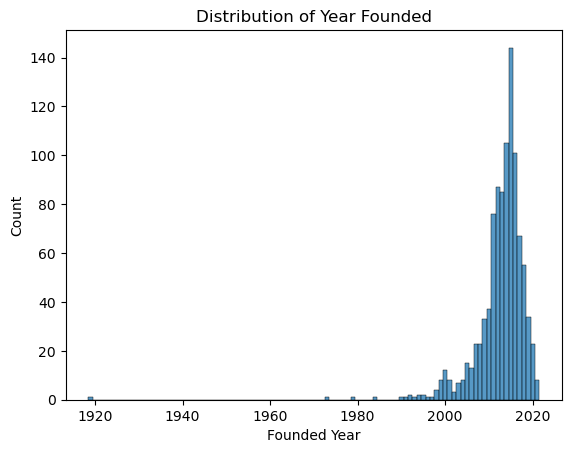

In [20]:
sns.histplot(companies['Founded Year'], discrete=True)
plt.title('Distribution of Year Founded')
plt.show()

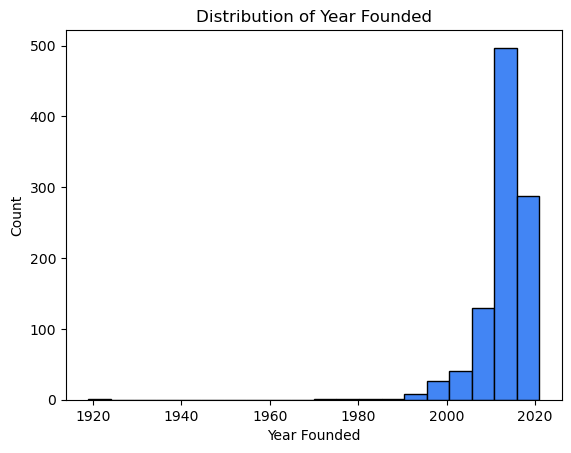

In [22]:
import matplotlib.pyplot as plt

plt.hist(companies['Founded Year'].dropna(), bins=20, color='#4285F4', edgecolor='black')
plt.title('Distribution of Year Founded')
plt.xlabel('Year Founded')
plt.ylabel('Count')
plt.show()

In [23]:
companies['Date Joined'] = pd.to_datetime(companies['Date Joined'])

In [24]:
companies.dtypes

Company                         str
Valuation ($B)                  str
Date Joined          datetime64[us]
Country                         str
City                            str
Industry                        str
Select Inverstors               str
Founded Year                float64
Total Raised                    str
Financial Stage                 str
Investors Count             float64
Deal Terms                  float64
Portfolio Exits             float64
dtype: object

In [25]:
companies['Month Joined'] = companies['Date Joined'].dt.month_name()

In [26]:
companies.head()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits,Month Joined
0,Bytedance,$140,2017-04-07,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0,April
1,SpaceX,$100.3,2012-12-01,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN,December
2,Stripe,$95,2014-01-23,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0,January
3,Klarna,$45.6,2011-12-12,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0,December
4,Epic Games,$42,2018-10-26,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0,October


In [29]:
companies['Years To Join'] = companies['Date Joined'].dt.year - companies['Founded Year']

In [30]:
companies.head()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits,Month Joined,Years To Join
0,Bytedance,$140,2017-04-07,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0,April,5.0
1,SpaceX,$100.3,2012-12-01,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN,December,10.0
2,Stripe,$95,2014-01-23,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0,January,4.0
3,Klarna,$45.6,2011-12-12,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0,December,6.0
4,Epic Games,$42,2018-10-26,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0,October,27.0


In [31]:
target_year = 2021
subset_companies = companies[companies['Date Joined'].dt.year == target_year]

In [32]:
subset_companies.head()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits,Month Joined,Years To Join
10,FTX,$32,2021-07-20,Bahamas,Fintech,"Sequoia Capital, Thoma Bravo, Softbank",NaN,2018.0,$1.829B,Acq,40.0,3.0,1.0,July,3.0
15,J&T Express,$20,2021-04-07,Indonesia,Jakarta,"Supply chain, logistics, & delivery","Hillhouse Capital Management, Boyu Capital, Se...",2015.0,$4.653B,NaN,9.0,3.0,NaN,April,6.0
24,OpenSea,$13.3,2021-07-20,United States,New York,E-commerce & direct-to-consumer,"Andreessen Horowitz, Thirty Five Ventures, Sou...",2017.0,$425.12M,NaN,26.0,2.0,NaN,July,4.0
32,GoodLeap,$12,2021-10-13,United States,Roseville,Internet software & services,"New Enterprise Associates, BDT Capital Partner...",2003.0,$1.8B,NaN,8.0,1.0,NaN,October,18.0
34,ZongMu Technology,$11.4,2021-06-03,China,Shanghai,Auto & transportation,"LTW Capital, Legend Capital, Qualcomm Ventures",2013.0,$210.83M,NaN,19.0,2.0,NaN,June,8.0


In [33]:
# Крок 1: Додаємо колонку з тимчасовим інтервалом (наприклад, місяцем за допомогою Month Joined)
subset_companies = subset_companies.copy()
subset_companies['Month'] = subset_companies['Date Joined'].dt.to_period('M')

# Крок 2: Групуємо за інтервалом (місяцем) та рахуємо кількість компаній, що стали єдинорогами
companies_by_interval = subset_companies.groupby('Month').size().reset_index(name='Company Count')

In [34]:
companies_by_interval.head()

,Month,Company Count
0,2021-01,34
1,2021-02,21
2,2021-03,50
3,2021-04,44
4,2021-05,44


In [40]:
# Крок 1: Фільтруємо за додатковим роком (наприклад, 2020)
additional_year = 2020
subset_additional = companies[companies['Date Joined'].dt.year == additional_year]

# Крок 2: Конкатенуємо новий підріз із попереднім
combined_subset = pd.concat([subset_companies, subset_additional]).copy()

# Крок 3: Додаємо колонку з часовим інтервалом (місяць)
combined_subset['Month'] = combined_subset['Date Joined'].dt.to_period('M')

# Крок 4: Переконуємось, що колонка Valuation ($B) має числовий формат
combined_subset['Valuation_Num'] = pd.to_numeric(combined_subset['Valuation ($B)'], errors='coerce')

# Крок 5: Групуємо за часовим інтервалом та обчислюємо середню оцінку
avg_valuation_by_interval = (
    combined_subset.groupby('Month')['Valuation_Num']
    .mean()
    .reset_index(name='Average Valuation')
)

In [41]:
avg_valuation_by_interval.head()

,Month,Average Valuation
0,2020-01,NaN
1,2020-02,NaN
2,2020-03,NaN
3,2020-04,NaN
4,2020-05,NaN


In [42]:
months_chronological = [
    'January', 'February', 'March', 'April', 'May', 'June', 
    'July', 'August', 'September', 'October', 'November', 'December'
]

In [43]:
print(months_chronological)

['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']


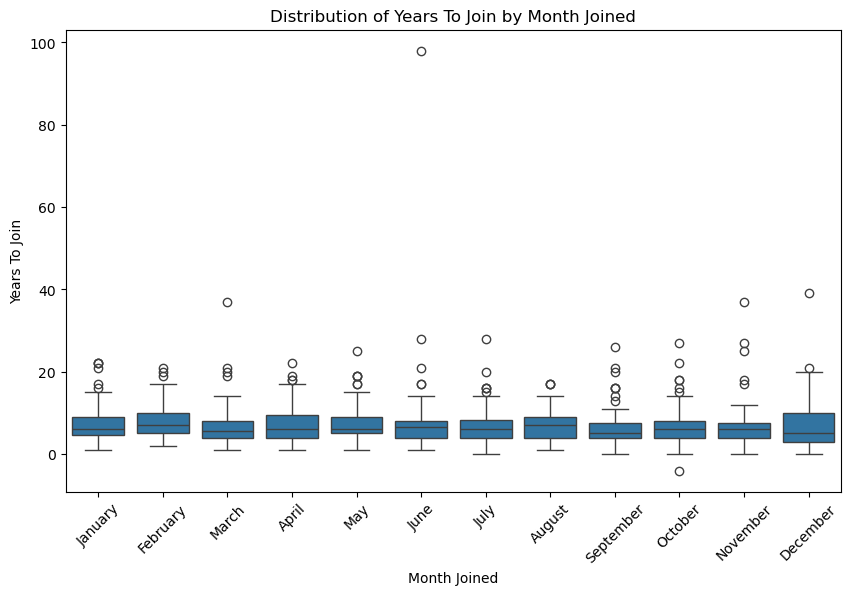

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=companies, 
    x='Month Joined', 
    y='Years To Join', 
    order=months_chronological
)
plt.title('Distribution of Years To Join by Month Joined')
plt.xticks(rotation=45)
plt.show()

Медіана: У більшості місяців медіана тримається приблизно на рівні 5–6 років. Тобто в середньому стартапу потрібно близько 5 років, щоб досягти оцінки в 1 мільярд доларів, незалежно від місяця заснування чи виходу на цей рівень.Викиди (точки зверху та знизу): Ми бачимо чимало окремих точок («викидів») угорі — це компанії-«довгожителі», яким знадобилося 20, 30 або навіть майже 40 років, щоб стати єдинорогами. Також у жовтні є один невеликий викид вниз (що технічно пов'язано з особливостями обчислення років чи окремими даними).   

<ipython-input-50-8de5ec294aa5>:10: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


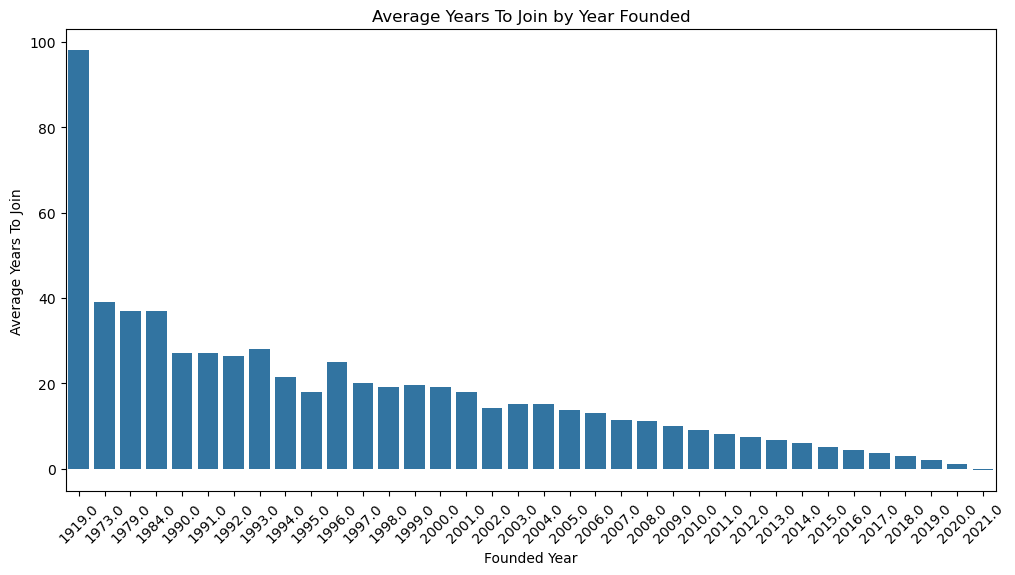

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the size of the plot.
plt.figure(figsize=(12, 6))

# Create bar plot to visualize the average number of years it took companies to reach unicorn status 
# with respect to when they were founded.
# Plot data from the `companies` DataFrame.
sns.barplot(
    data=companies, 
    x='Founded Year', 
    y='Years To Join', 
    ci=None # Вимикаємо інтервали довіри для чистішого вигляду
)

# Set title
plt.title('Average Years To Join by Year Founded')

# Set x-axis label
plt.xlabel('Founded Year')

# Set y-axis label
plt.ylabel('Average Years To Join')

# Rotate the labels on the x-axis as a way to avoid overlap in the positions of the text.  
plt.xticks(rotation=45)

# Display the plot.
plt.show()

<ipython-input-51-33cc23139140>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


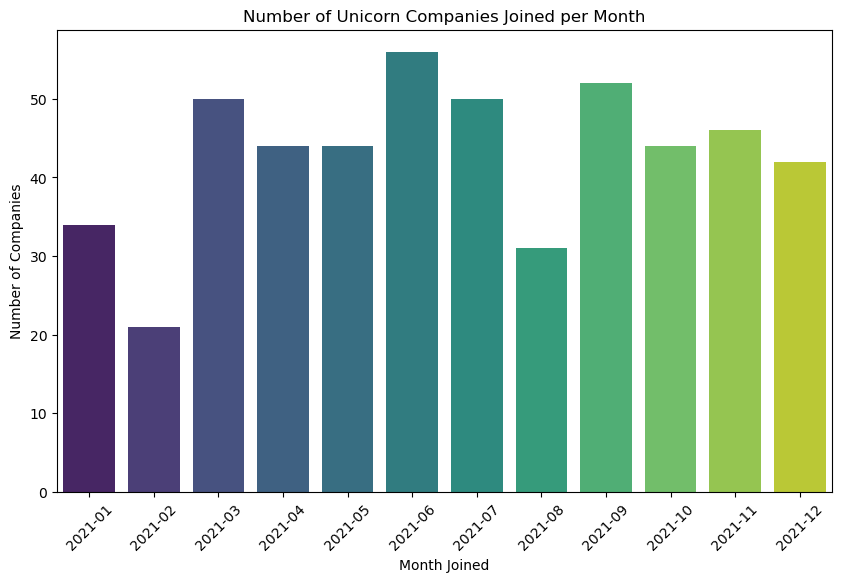

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the size of the plot.
plt.figure(figsize=(10, 6))

# Create bar plot to visualize number of companies that joined per interval for the year of interest.
sns.barplot(
    data=companies_by_interval,
    x='Month',
    y='Company Count',
    palette='viridis'
)

# Set the x-axis label.
plt.xlabel('Month Joined')

# Set the y-axis label.
plt.ylabel('Number of Companies')

# Set the title.
plt.title('Number of Unicorn Companies Joined per Month')

# Rotate labels on the x-axis as a way to avoid overlap in the positions of the text.  
plt.xticks(rotation=45)

# Display the plot.
plt.show()

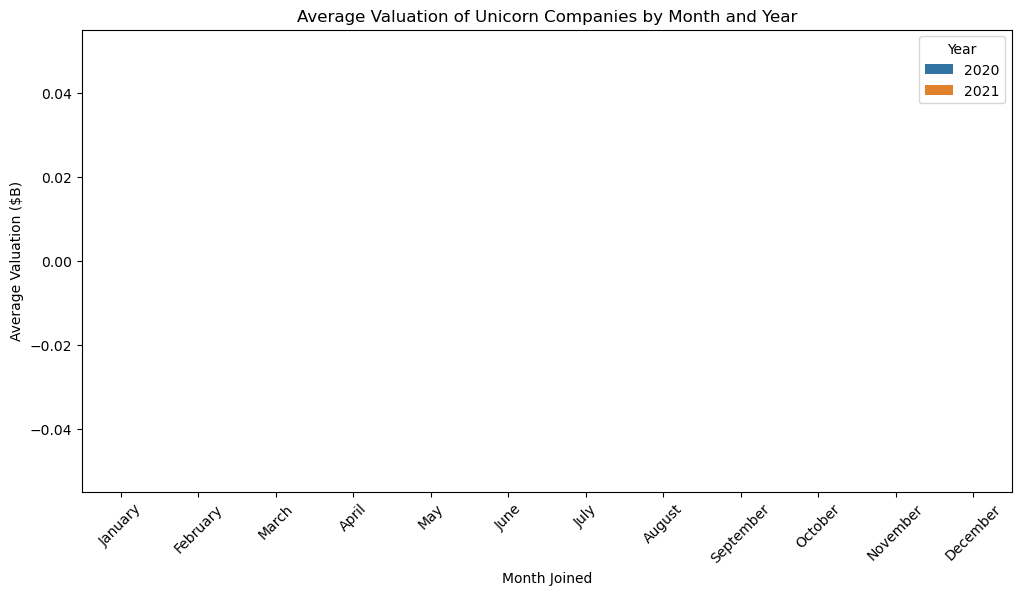

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

# Крок 1: Готуємо згруповані дані за роком і місяцем
combined_subset = combined_subset.copy()
combined_subset['Join Year'] = combined_subset['Date Joined'].dt.year.astype(str)
combined_subset['Join Month'] = combined_subset['Date Joined'].dt.strftime('%B')

# Групуємо за роком та місяцем, обчислюючи середню вартість
grouped_avg = (
    combined_subset.groupby(['Join Month', 'Join Year'])['Valuation_Num']
    .mean()
    .reset_index(name='Average Valuation')
)

# Set the size of the plot.
plt.figure(figsize=(12, 6))

# Create a grouped bar plot using the pre-aggregated data
sns.barplot(
    data=grouped_avg,
    x='Join Month',
    y='Average Valuation',
    hue='Join Year',
    order=months_chronological
)

# Set the x-axis label.
plt.xlabel('Month Joined')

# Set the y-axis label.
plt.ylabel('Average Valuation ($B)')

# Set the title.
plt.title('Average Valuation of Unicorn Companies by Month and Year')

# Rotate labels on the x-axis to avoid overlap
plt.xticks(rotation=45)

# Move legend and display cleanly
plt.legend(title='Year')

# Display the plot.
plt.show()

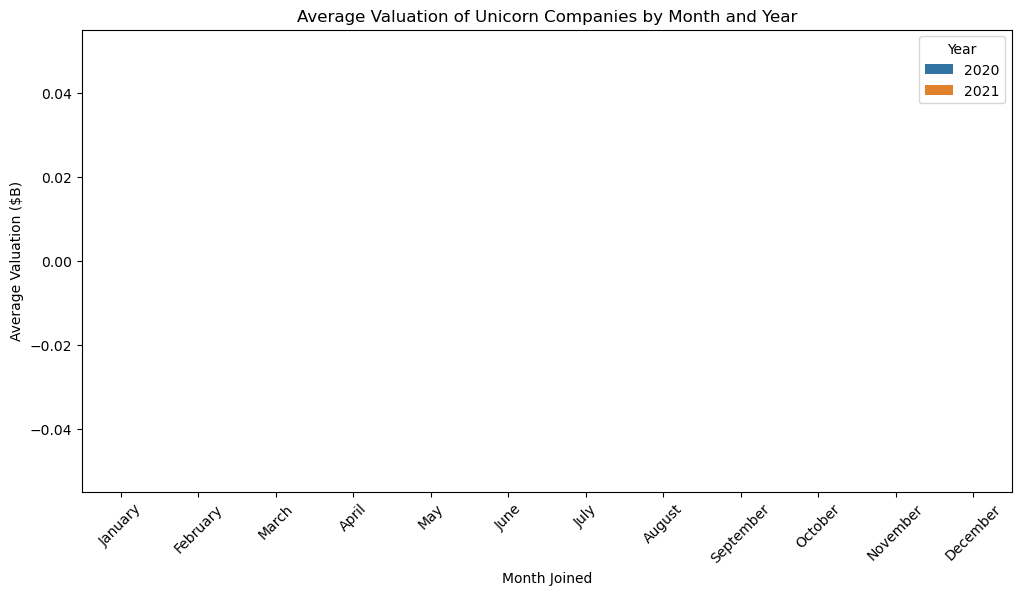

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

# Крок 1: Копіюємо та коректно очищуємо колонку Valuation ($B) від доларів та літер
combined_subset = combined_subset.copy()

# Якщо дані все ще у вигляді рядків зі знаками, очистимо їх:
if combined_subset['Valuation ($B)'].dtype == object:
    combined_subset['Valuation_Num'] = (
        combined_subset['Valuation ($B)']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.replace('B', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
        .astype(float)
    )
else:
    combined_subset['Valuation_Num'] = pd.to_numeric(combined_subset['Valuation ($B)'], errors='coerce')

# Створюємо додаткові колонки для місяця та року
combined_subset['Join Year'] = combined_subset['Date Joined'].dt.year.astype(str)
combined_subset['Join Month'] = combined_subset['Date Joined'].dt.strftime('%B')

# Групуємо дані
grouped_avg = (
    combined_subset.groupby(['Join Month', 'Join Year'])['Valuation_Num']
    .mean()
    .reset_index(name='Average Valuation')
)

# Set the size of the plot.
plt.figure(figsize=(12, 6))

# Create a grouped bar plot
sns.barplot(
    data=grouped_avg,
    x='Join Month',
    y='Average Valuation',
    hue='Join Year',
    order=months_chronological
)

# Set the x-axis label.
plt.xlabel('Month Joined')

# Set the y-axis label.
plt.ylabel('Average Valuation ($B)')

# Set the title.
plt.title('Average Valuation of Unicorn Companies by Month and Year')

# Rotate labels on the x-axis to avoid overlap
plt.xticks(rotation=45)

# Move legend and display cleanly
plt.legend(title='Year')

# Display the plot.
plt.show()